# Understanding Plotly from the Ground Up
## A beginner-friendly, interactive Jupyter Notebook

### What you will learn
This notebook focuses on understanding **Plotly itself**, before moving into more advanced chart projects.

By the end, you should be able to:
- Explain what Plotly is and when to use it.
- Understand the difference between Plotly Express and Graph Objects.
- Read the main parts of a Plotly chart.
- Map data columns to chart axes, colors, sizes, and hover details.
- Customize titles, labels, themes, markers, and legends.
- Use hover, zoom, pan, and selection tools.
- Understand traces, figures, and layouts.
- Save charts as HTML and, optionally, static image files.

### How each lesson is organized
Each major lesson follows this pattern:

**Theory → Question → Code with comments → Expected output → Code explanation → Output explanation**

The charts are generated when you run the code cells. Plotly's interactive controls work in a compatible Jupyter environment.

# 1. What is Plotly?

## Theory
**Plotly** is a Python visualization library for building interactive, web-based charts. Compared with a basic static chart, a Plotly chart commonly supports:
- **Hover:** point to a mark to inspect its values.
- **Zoom:** magnify a region.
- **Pan:** move around a zoomed chart.
- **Legend interaction:** click legend items to hide or show series.
- **Export:** save a chart image from the chart toolbar, or save the chart as an HTML file.

Plotly has two commonly used Python interfaces:

| Interface | Best for |
|---|---|
| `plotly.express` (`px`) | Quick charts with concise code |
| `plotly.graph_objects` (`go`) | Fine-grained control over traces and layout |

A **figure** is the complete chart. It contains one or more **traces** (the data being drawn) and a **layout** (titles, axes, legend, spacing, and other presentation settings).

## Question
Import Plotly and print the installed version so you can confirm that it is available.

In [1]:
# Install these packages if your environment does not already have them.
%pip install plotly pandas numpy

Note: you may need to restart the kernel to use updated packages.


### Code explanation
- `%pip install` installs Plotly and the supporting data libraries in the active notebook environment.
- You can skip this cell if the packages are already installed.

### Expected output and explanation
The cell prints package installation messages. If the packages are already installed, the output may say they are already satisfied. No chart is created yet.

In [2]:
# Import Plotly's two main charting interfaces and data libraries.
import plotly
import plotly.express as px
import plotly.graph_objects as go
import pandas as pd
import numpy as np

# Display the installed Plotly version.
print("Plotly version:", plotly.__version__)

Plotly version: 6.3.0


### Code explanation
- `import plotly` gives access to package-level information such as the version.
- `plotly.express as px` provides high-level chart functions.
- `plotly.graph_objects as go` provides lower-level chart building blocks.
- `pandas` manages tabular data; `numpy` helps create numerical examples.
- `plotly.__version__` reports the installed version.

### Output explanation
You should see a line similar to `Plotly version: 6.x.x`. Your exact version may differ. If imports fail, run the installation cell and, if necessary, restart the kernel.

# 2. Understand the data first

## Theory
Most charts start with structured data, often a pandas DataFrame. Each **row** represents an observation, and each **column** represents a variable. Plotly maps columns to visual properties such as x-position, y-position, color, marker size, and hover text.

## Question
Create a small table of product sales and inspect its rows and column names before plotting it.

In [3]:
# Create a small example dataset.
sales_df = pd.DataFrame({
    "Product": ["Laptop", "Phone", "Tablet", "Monitor", "Keyboard"],
    "Units_Sold": [18, 35, 22, 14, 42],
    "Revenue": [18000, 14000, 6600, 5600, 2100],
    "Category": ["Computer", "Mobile", "Mobile", "Computer", "Accessory"]
})
# Display the data table.
display(sales_df)
# Print the number of rows and columns, and the column names.
print("Shape (rows, columns):", sales_df.shape)
print("Columns:", list(sales_df.columns))

,Product,Units_Sold,Revenue,Category
0,Laptop,18,18000,Computer
1,Phone,35,14000,Mobile
2,Tablet,22,6600,Mobile
3,Monitor,14,5600,Computer
4,Keyboard,42,2100,Accessory


Shape (rows, columns): (5, 4)
Columns: ['Product', 'Units_Sold', 'Revenue', 'Category']


### Code explanation
- `pd.DataFrame()` creates a table from column lists.
- `display(sales_df)` renders the table in Jupyter.
- `.shape` returns a tuple containing row count and column count.
- `.columns` contains the column names; `list()` converts them to a regular Python list.

### Output explanation
The table contains five products and four columns. The shape should be `(5, 4)`. These column names will be referenced in later Plotly code, so spelling and capitalization matter.

# 3. Your first Plotly chart with Plotly Express

## Theory
Plotly Express is a good starting point because one function call can create a complete chart. For example, `px.bar()` creates a bar chart from a DataFrame. Its `x` and `y` arguments tell Plotly which columns to visualize.

## Question
Create an interactive bar chart showing revenue by product.

In [4]:
# Use Plotly Express to map products to the x-axis and revenue to the y-axis.
fig = px.bar(
    sales_df,
    x="Product",                 # category labels along the horizontal axis
    y="Revenue",                 # numerical bar heights
    title="Revenue by Product",  # chart title
    color="Category",            # color bars by product category
    hover_data=["Units_Sold"]    # include units sold in the hover tooltip
)

# Display the chart.
fig.show()

### Code explanation
- `px.bar()` builds a bar chart from the DataFrame.
- `x="Product"` makes each product a category on the horizontal axis.
- `y="Revenue"` controls bar height.
- `title` adds a heading.
- `color="Category"` uses different colors for categories.
- `hover_data` adds `Units_Sold` to the hover tooltip.
- The variable `fig` stores the complete figure; `fig.show()` displays it.

### Output explanation
You should see one bar per product. Keyboard has the highest revenue in this sample? Check the values carefully: Laptop has revenue 18,000, which is the highest, followed by Phone at 14,000. Hover over bars to inspect the exact revenue and units sold. Click a category in the legend to toggle that category.

# 4. Plotly Express versus Graph Objects

## Theory
Plotly Express is concise and data-frame-oriented. Graph Objects lets you build a figure by adding individual traces and configuring the layout explicitly.

A **trace** is one plotted data series or layer. A figure can contain multiple traces, such as a line and a set of markers.

## Question
Build the same sales chart using Graph Objects to understand the extra structure.

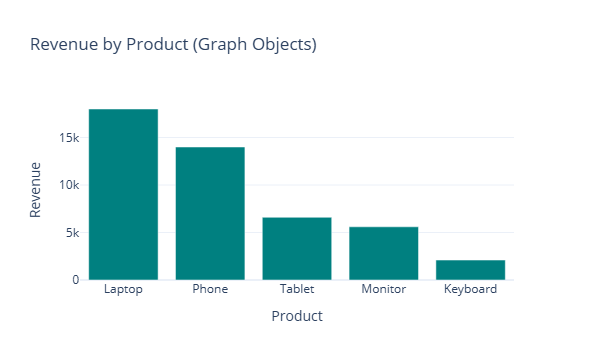

In [16]:
# Start with an empty figure.
fig_go = go.Figure()

# Add one bar trace. x and y are explicit lists from the DataFrame.
fig_go.add_trace(
    go.Bar(
        x=sales_df["Product"],
        y=sales_df["Revenue"],
        name="Revenue",
        marker_color="teal",
        hovertemplate="Product: %{x}<br>Revenue: %{y:,}<extra></extra>",
        
    )
)

# Configure the layout separately from the data trace.
fig_go.update_layout(
    title="Revenue by Product (Graph Objects)",
    xaxis_title="Product",
    yaxis_title="Revenue",
    template="plotly_white"
)

# Render the figure.
fig_go.show()

### Code explanation
- `go.Figure()` creates an empty figure.
- `go.Bar(...)` defines a bar trace.
- `add_trace()` inserts the trace into the figure.
- `marker_color` sets the bar color.
- `hovertemplate` customizes tooltip content. `<br>` inserts a new line, `%{x}` refers to the x value, and `%{y:,}` formats the y value with thousands separators.
- `update_layout()` configures the title, axis titles, and theme independently.

### Output explanation
The chart shows the same revenue values as the Plotly Express chart, but it is constructed in more explicit steps. Use Express for quick standard charts; use Graph Objects when you need detailed control over traces, axes, or figure structure.

# 5. Mapping columns to visual properties

## Theory
Plotly can encode data through more than just x and y:
- `color`: distinguish groups or represent a numerical scale.
- `size`: vary marker size according to a numeric column.
- `symbol`: distinguish groups using marker shapes.
- `hover_data`: show additional values without adding more axes.

A scatter plot is useful when you want to compare two numerical variables and investigate possible relationships.

## Question
Plot units sold against revenue, use marker size to show units sold, and color points by category.

In [6]:
# Each point represents one product.
fig_scatter = px.scatter(
    sales_df,
    x="Units_Sold",
    y="Revenue",
    color="Category",
    size="Units_Sold",
    hover_name="Product",
    hover_data=["Product"],
    title="Units Sold vs Revenue",
    labels={
        "Units_Sold": "Units sold",
        "Revenue": "Revenue"
    }
)

fig_scatter.show()

### Code explanation
- `px.scatter()` creates a scatter plot.
- `x` and `y` choose the two numerical dimensions.
- `color="Category"` assigns category colors.
- `size="Units_Sold"` makes markers larger for products with more units sold.
- `hover_name="Product"` uses the product name as the tooltip heading.
- `labels` replaces raw column names with reader-friendly axis labels.

### Output explanation
Each point represents a product. Points farther right represent more units sold; points higher up represent more revenue. Color distinguishes product categories and marker size also reflects units sold. The plot may suggest a relationship, but five example products are not enough to establish a general business rule.

# 6. Customize the layout

## Theory
The layout controls the presentation around the data: chart title, axis labels, legend, background theme, margins, and dimensions. Plotly's `update_layout()` and axis update methods can be applied after creating a figure.

## Question
Improve the bar chart with clearer labels, a theme, and a y-axis that starts at zero.

In [7]:
# Reuse the earlier Plotly Express figure and customize its layout.
fig_custom = px.bar(
    sales_df,
    x="Product",
    y="Revenue",
    color="Category",
    title="Product Revenue Comparison"
)

fig_custom.update_layout(
    template="plotly_white",          # clean white chart background
    title_x=0.5,                       # center the title
    legend_title_text="Product type",  # change legend heading
    height=500                         # set chart height in pixels
)

fig_custom.update_xaxes(title_text="Product name")
fig_custom.update_yaxes(title_text="Revenue (currency units)", rangemode="tozero")

fig_custom.show()

### Code explanation
- `update_layout()` changes figure-level presentation settings.
- `template="plotly_white"` applies a white theme.
- `title_x=0.5` centers the title horizontally.
- `legend_title_text` renames the legend title.
- `height=500` sets the figure height.
- `update_xaxes()` and `update_yaxes()` set axis labels.
- `rangemode="tozero"` ensures the y-axis includes zero, which is usually helpful for bar comparisons.

### Output explanation
The chart retains the same revenue data but has a clearer presentation. The y-axis starts at zero so bar heights are easier to compare fairly. Try changing the template to `"plotly_dark"` and rerunning the cell.

# 7. Understanding interactivity

## Theory
Plotly's interactivity is built into its rendered chart. Depending on chart type and display environment, the toolbar can offer zoom, pan, box or lasso selection, autoscale, and image export. Hover tooltips are controlled by settings such as `hover_data`, `hover_name`, and `hovertemplate`.

## Question
Create a scatter plot with detailed hover text and practice the built-in chart controls.

In [8]:
# Make a simple scatter plot with customized hover information.
fig_interactive = px.scatter(
    sales_df,
    x="Units_Sold",
    y="Revenue",
    color="Category",
    hover_name="Product",
    hover_data={
        "Units_Sold": True,
        "Revenue": ":,.0f",  # display revenue with thousands separators and no decimals
        "Category": True
    },
    title="Explore Product Sales Interactively"
)

fig_interactive.show()

### Code explanation
- The scatter plot maps units sold to x and revenue to y.
- `hover_name` makes the product name prominent in the tooltip.
- In the `hover_data` dictionary, `True` includes a field and `":,.0f"` formats revenue with a thousands separator and zero decimal places.
- `show()` renders the chart with its interactive controls.

### Output explanation
Hover over a point to see the product and its values. Use the toolbar to zoom into an area, pan, reset the axes, or download a static image. Click a legend entry to hide or show a category. The exact toolbar icons can vary by Plotly version and notebook environment.

# 8. Multiple traces in one figure

## Theory
A figure can contain multiple traces. This is useful for comparing series on the same axes. Each trace has its own data and can have a legend entry.

## Question
Compare actual and target revenue using two line traces.

In [9]:
# Create a compact dataset with actual and target revenue.
comparison = pd.DataFrame({
    "Month": ["Jan", "Feb", "Mar", "Apr", "May", "Jun"],
    "Actual": [120, 135, 128, 150, 162, 170],
    "Target": [125, 130, 135, 140, 155, 165]
})

# Create an empty figure and add two separate traces.
fig_multi = go.Figure()

fig_multi.add_trace(
    go.Scatter(
        x=comparison["Month"],
        y=comparison["Actual"],
        mode="lines+markers",
        name="Actual revenue"
    )
)

fig_multi.add_trace(
    go.Scatter(
        x=comparison["Month"],
        y=comparison["Target"],
        mode="lines+markers",
        name="Target revenue",
        line=dict(dash="dash")
    )
)

# Configure the shared layout.
fig_multi.update_layout(
    title="Actual vs Target Revenue",
    xaxis_title="Month",
    yaxis_title="Revenue (illustrative units)",
    template="plotly_white"
)

fig_multi.show()

### Code explanation
- `comparison` contains one month column and two numerical series.
- `go.Figure()` creates the figure container.
- Each `add_trace()` adds one series to the same axes.
- `mode="lines+markers"` shows both connecting lines and data markers.
- `name` sets the legend label.
- `line=dict(dash="dash")` draws the target series with a dashed line.
- `update_layout()` labels the axes and sets the title.

### Output explanation
Two lines appear: actual revenue and target revenue. The legend lets you hide or show either series. Comparing the lines makes it easy to see which months are above or below target.

# 9. Save and share a Plotly chart

## Theory
A Plotly figure can be saved as an **HTML file** that retains interactivity in a web browser. A static PNG or other image format is also possible, but static export may require the optional `kaleido` package.

## Question
Save the interactive sales chart as an HTML file.

In [10]:
# Save the chart as a standalone HTML file in the notebook's current directory.
html_file = "product_revenue_interactive.html"
fig_custom.write_html(html_file, include_plotlyjs=True)

print("Saved interactive chart to:", html_file)

Saved interactive chart to: product_revenue_interactive.html


### Code explanation
- `write_html()` writes the figure to an HTML file.
- `include_plotlyjs=True` embeds the Plotly JavaScript library, making the file more portable offline, although the file is larger.
- `html_file` stores the filename for reuse.
- `print()` confirms the target filename.

### Output explanation
You should see `Saved interactive chart to: product_revenue_interactive.html`. The HTML file is written to the notebook's current working directory. Open it in a web browser to use the chart outside Jupyter.

In [11]:
# OPTIONAL: Save a static PNG image.
# If this cell reports that Kaleido is missing, install it with:
# %pip install --upgrade kaleido
# Then restart the kernel if requested and run this cell again.

# fig_custom.write_image("product_revenue.png")

### Optional static export explanation
The PNG export line is commented out, so it will not run unless you remove the `#`. Static image export can require Kaleido and a compatible environment. The HTML export above is the simplest way to share an interactive chart.

# 10. Quick reference

| Goal | Plotly function or setting |
|---|---|
| Bar chart | `px.bar()` |
| Scatter plot | `px.scatter()` |
| Line chart | `px.line()` or `go.Scatter(mode="lines")` |
| Box plot | `px.box()` |
| Histogram | `px.histogram()` |
| Build a figure manually | `go.Figure()` |
| Add a trace | `fig.add_trace()` |
| Change titles and theme | `fig.update_layout()` |
| Change axis labels | `fig.update_xaxes()` / `fig.update_yaxes()` |
| Display a chart | `fig.show()` |
| Save interactive HTML | `fig.write_html("chart.html")` |

## Final practice questions
1. Change the bar chart to show `Units_Sold` instead of `Revenue`.
2. Change the scatter plot to color by a different column.
3. Add a third trace to the actual-versus-target line chart.
4. Change the theme to `"plotly_dark"`.
5. Save a different chart as an HTML file.

## Key takeaway
Think of a Plotly chart as **data + traces + layout + interaction**. Plotly Express helps you create common charts quickly, while Graph Objects gives you detailed control over how each trace and the overall figure behave.